# Walmart Hurricane Project: Data Cleaning

Owner: Henna

Progress: Done Q1

In [1]:
import pandas as pd
import numpy as np, re, os
import matplotlib.pyplot as plt

def find_data(filename, folders=('data', '../data', '../../data', '/content/walmart-hurricane-project/data', '/content/data', '/kaggle/input', '/content')):
  for folder in folders:
      if os.path.exists(os.path.join(folder, filename)):
          return os.path.join(folder, filename)
  raise FileNotFoundError(f'{filename} not found. Put data files in repo in the data/ folder.')

DECISIONS = [] # Storing every cleaning decision made
COUNTS = [] # Rows before then after each step

def log(step, decision, rows_affected, dropped=False):
  # dropped = True means those rows were removed and validation will use it to check the row math
  DECISIONS.append({'step': step, 'decision': decision, 'rows': int(rows_affected), 'dropped': dropped})
  print(f'[{step}] {decision} ({int(rows_affected)} row(s))')

def run_step(name, fn, df, *args):
  # Used to run a cleaning function and record the row count before then after
  before = len(df)
  out = fn(df, *args)
  COUNTS.append({'step': name, 'rows_before': before, 'rows_after': len(out)})
  return out

def show_log():
  return pd.DataFrame(DECISIONS)

def show_counts():
  return pd.DataFrame(COUNTS)

pd.set_option('display.max_colwidth', 90)
print('pandas', pd.__version__)

pandas 2.2.3


# 1. Extract: Loading the data

In [2]:
def extract():
  tx = pd.read_csv(find_data('walmart_transactions.csv'))
  stores = pd.read_csv(find_data('store_locations.csv'))
  catalog = pd.read_csv(find_data('product_catalog.csv'))
  dcs = pd.read_csv(find_data('distribution_centers.csv'))
  print(f'transactions: {len(tx):,} rows | stores: {len(stores)} | catalog: {len(catalog)} | distribution centers: {len(dcs)}')
  return tx, stores, catalog, dcs

tx_raw, stores_raw, catalog_raw, dcs_raw = extract()
tx_raw.head()

transactions: 25,562 rows | stores: 14 | catalog: 45 | distribution centers: 5


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


In [3]:
# Raw profile to see the uncleaned version later
print(tx_raw.dtypes, '\n')
print('nulls per column (pandas default null detection):')
print(tx_raw.isnull().sum(), '\n')
print('exact duplicate rows:', tx_raw.duplicated().sum())
print('transaction_id repeats:', tx_raw['transaction_id'].duplicated().sum())

# Hidden missing values as strings because pandas doesn't treat str types as null
for col in tx_raw.select_dtypes(include=['object', 'string']).columns:
  s = tx_raw[col].dropna().astype(str).str.strip().str.lower()
  hits = s[s.isin(['', 'none', 'null', 'n/a', 'na', 'nan', '-', '--', '?', 'unknown', 'missing', 'tbd'])]
  if len(hits):
      print(f'hidden placeholders in {col}:', hits.value_counts().to_dict())

transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object 

nulls per column (pandas default null detection):
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64 

exact duplicate rows: 30
transaction_id repeats: 30


# 2. Transform:

## Missing values

In [4]:
PLACEHOLDERS = {'', 'none', 'null', 'n/a', 'na', 'nan', '-', '--', '?', 'unknown', 'missing', 'tbd'}

def standardize_missing(df):
  # Turn placeholder strings into real NaN, trim spaces
  out = df.copy()
  for col in out.select_dtypes(include='object').columns:
    stripped = out[col].astype('string').str.strip()
    is_placeholder = stripped.str.lower().isin(PLACEHOLDERS) & out[col].notna()
    out[col] = stripped.where(~is_placeholder, other=pd.NA).astype(object)
    out[col] = out[col].where(out[col].notna(), np.nan)
    if is_placeholder.sum():
      log('missing_placeholders', f'{col}: {int(is_placeholder.sum())} placeholder strings converted to NaN',
        is_placeholder.sum())
  log('whitespace', 'checked all text cols for extra spaces', len(out))
  return out

def handle_required_nulls(df):
  # Dropping rows with no sku because they can't be tied to a product, other nulls kept and handled based on the step that owns that col
  out = df[df['sku'].notna()].copy()
  log('sku_missing', 'dropped rows with no sku (no tie to a product)', len(df) - len(out), dropped=True)
  for col, why in [('timestamp', 'kept; the sale is real, just cant sit on a day'),
                   ('unit_price', 'kept as NaN; we cannot make up a price. Revenue questions will skip these rows'),
                   ('store_id', 'kept as NaN; counts toward totals')]:
    if col in out.columns:
      log(f'null_{col}', f'{col} nulls {why}', out[col].isna().sum())
  return out

## Duplicates

In [5]:
def drop_duplicates(df):
  out = df.drop_duplicates().copy()
  log('duplicates', 'dropped exact duplicate rows (kept first copy)', len(df) - len(out), dropped=True)
  # Reporting same id with different contents
  repeated_ids = out['transaction_id'].duplicated().sum()
  print('rows sharing a transaction_id after dedupe:', repeated_ids)
  log('duplicate_ids', 'rows sharing a transaction_id with diff contents (only reported)', repeated_ids)
  return out

## Prices

In [6]:
def fix_prices(df):
  out = df.copy()
  cleaned = out['unit_price'].astype('string').str.replace(r'[$,\s]', '', regex=True)
  out['unit_price'] = pd.to_numeric(cleaned, errors='coerce').astype(float)
  new_nan = out['unit_price'].isna().sum() - df['unit_price'].isna().sum()
  log('prices', 'stripped $, commas, spaces and converted unit_price to float', len(out))
  log('prices_unparseable', 'values that could not become numbers', max(new_nan, 0))
  log('prices_nonpositive', 'unit_price <= 0 (only reported)', (out['unit_price'] <= 0).sum())
  return out

In [7]:
def fix_quantity(df):
  out = df.copy()
  out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
  # Drop quantity if none, cant add to total
  n_missing = out['quantity'].isna().sum()
  out = out[out['quantity'].notna()].copy()
  log('quantity_missing', 'dropped rows with no / unreadable quantity', n_missing, dropped=True)
  # Flag negatives but keep them
  out['quantity'] = out['quantity'].astype(int)
  out['is_return'] = out['quantity'] < 0
  log(
    'quantity_negative',
    'kept negative quantities as likely returns/adjustments; flagged is_return=True',
    out['is_return'].sum()
  )
  log('quantity_zero', 'quantity 0 (kept, reported only)', (out['quantity'] == 0).sum())
  return out

In [8]:
def norm_store_id(value):
  # FL239, fl-239, 'FL 239', FL_239 -> FL-239 (3 digits, matches store_locations)
  if pd.isna(value):
      return np.nan
  key = re.sub(r'[^A-Z0-9]', '', str(value).upper())
  m = re.match(r'^([A-Z]+)0*(\d+)$', key)
  return f'{m.group(1)}-{int(m.group(2)):03d}' if m else key

def fix_store_ids(df, stores):
  out = df.copy()
  before = out['store_id'].nunique()
  out['store_id'] = out['store_id'].apply(norm_store_id)
  log('store_id', f'normalized store ids to XX-### ({before} variants -> {out["store_id"].nunique()})', len(out))
  valid = set(stores['store_id'])
  unmatched = out[out['store_id'].notna() & ~out['store_id'].isin(valid)]['store_id']
  if len(unmatched):
      print('   WARNING store ids not in store_locations:', sorted(unmatched.unique()))
  log('store_id_unmatched', 'rows whose store_id is not in store_locations (kept, reported)', len(unmatched))
  return out

In [9]:
def clean_stores(stores):
  """store_locations has the same store written two ways (FL239, FL_287), state spelled 3 ways, and one store with no coordinates."""
  out = stores.copy()
  n0 = len(out)
  out['store_id'] = out['store_id'].apply(norm_store_id)
  out['state'] = out['state'].astype(str).str.strip().replace({'Florida': 'FL', 'Fla.': 'FL'})
  for col in ['store_name', 'city', 'region']:
      out[col] = out[col].astype('string').str.strip()
  out = out.drop_duplicates().reset_index(drop=True)
  log('stores_duplicates', f'store_locations: same store written two ways, kept one ({n0} rows -> {len(out)})', n0 - len(out))
  log('stores_state', 'state spellings (Florida / Fla. / FL) standardized to FL', len(out))
  missing_xy = out[out['latitude'].isna() | out['longitude'].isna()]['store_id'].tolist()
  # Decision: not inventing coordinates, helping with Q4
  log('stores_no_coordinates', f'stores with no lat/lon (left blank, reported): {missing_xy}', len(missing_xy))
  assert out['store_id'].is_unique, 'store ids still repeat in store_locations'
  return out

def clean_dcs(dcs):
  out = dcs.copy()
  raw = out['surge_capacity'].astype(str)
  out['surge_capacity_approx'] = raw.str.contains('~')
  out['surge_capacity'] = pd.to_numeric(raw.str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
  log('dc_surge_capacity', 'surge_capacity had "~" in front of a number; stripped it, flagged surge_capacity_approx', out['surge_capacity_approx'].sum())
  log('dc_missing_cost', 'cost_per_shipment missing (left as NaN, not invented)', out['cost_per_shipment'].isna().sum())
  return out

In [10]:
def fix_timestamps(df):
  out = df.copy()
  parsed = pd.to_datetime(out['timestamp'], format='mixed', errors='coerce')
  unparseable = (out['timestamp'].notna() & parsed.isna()).sum()
  out['timestamp'] = parsed
  out['date'] = out['timestamp'].dt.normalize()
  # Kept rows with no timestamp
  log('timestamps', 'parsed mixed formats; kept rows with no timestamp (date = NaT)', out['timestamp'].isna().sum())
  log('timestamps_unparseable', 'text timestamps that would not parse (now NaT)', unparseable)
  in_range = out['date'].between('2024-09-01', '2024-09-30') | out['date'].isna()
  log('timestamps_out_of_range', 'dates outside Sept 2024 (check day/month swap)', (~in_range).sum())
  print('date range:', out['date'].min().date(), 'to', out['date'].max().date())
  return out

## Categories

In [11]:
CATEGORY_MAP = {
  'breakfast': 'Breakfast', 'breakfastfoods': 'Breakfast',
  'emergency': 'Emergency', 'emergencysupplies': 'Emergency',
  'entertainment': 'Entertainment', 'gamesentertainment': 'Entertainment',
  'grocery': 'Grocery', 'groceries': 'Grocery',
  'household': 'Household', 'householdessentials': 'Household',
  'electronics': 'Electronics',
  'health': 'Health', 'healthwellness': 'Health',
  'baby': 'Baby', 'babyproducts': 'Baby',
  'alcohol': 'Alcohol', 'alcoholicbeverages': 'Alcohol', 'alcoholic': 'Alcohol',
  'snacks': 'Snacks', 'snack': 'Snacks',
}

def fix_categories(df):
  """37 spellings -> 10 categories. Lowercase + letters only, then look up in CATEGORY_MAP."""
  out = df.copy()
  before = out['category'].nunique()
  key = out['category'].astype(str).str.lower().str.replace(r'[^a-z]', '', regex=True)
  mapped = key.map(CATEGORY_MAP)
  leftover = sorted(out.loc[mapped.isna(), 'category'].dropna().unique())
  if leftover:
      print('   REVIEW these categories are not in CATEGORY_MAP (kept, title-cased):', leftover)
  out['category'] = mapped.fillna(out['category'].astype(str).str.strip().str.title())
  log('category', f'normalized category labels ({before} variants -> {out["category"].nunique()})', len(out))
  conflicts = (out.groupby('sku')['category'].nunique() > 1).sum()
  log('category_conflicts', 'skus that still have more than one category (should be 0)', conflicts)
  return out

## SKU and Product Name Consolidation

In [12]:
SKU_MAP = {
  # Strawberry Pop-Tarts
  'PT-12': ('POPTART-STRAWBERRY', 'Strawberry Pop-Tarts'),
  'SKU#459812': ('POPTART-STRAWBERRY', 'Strawberry Pop-Tarts'),
  'POPTART-STRAW': ('POPTART-STRAWBERRY', 'Strawberry Pop-Tarts'),
  'PT_STRAWBERRY': ('POPTART-STRAWBERRY', 'Strawberry Pop-Tarts'),

  # Bottled Water
  'WTR-24': ('WATER-24PK', 'Bottled Water 24-Pack'),
  'WATER24PK': ('WATER-24PK', 'Bottled Water 24-Pack'),
  'WTR_24PK': ('WATER-24PK', 'Bottled Water 24-Pack'),

  # AA Batteries
  'BATT-100': ('BATTERY-AA4', 'AA Batteries 4-Pack'),
  'BAT-AA4': ('BATTERY-AA4', 'AA Batteries 4-Pack'),
  'BATT_AA_4PK': ('BATTERY-AA4', 'AA Batteries 4-Pack'),

  # Flashlights
  'FLASH-01': ('FLASHLIGHT-LED', 'LED Flashlight'),
  'LED-FLASH': ('FLASHLIGHT-LED', 'LED Flashlight'),

  # Light Beer
  'BEER-24': ('LIGHTBEER-24', 'Light Beer 24-Pack'),
  'LTBEER24': ('LIGHTBEER-24', 'Light Beer 24-Pack'),

  # Monopoly
  'BG-MONO': ('MONOPOLY', 'Monopoly Board Game'),
   'MONOPOLY-01': ('MONOPOLY', 'Monopoly Board Game'),
  'GAME-MONO': ('MONOPOLY', 'Monopoly Board Game'),

  # Playing Cards
  'CARDS-01': ('PLAYING-CARDS', 'Playing Cards'),
  'PLAYCARD-STD': ('PLAYING-CARDS', 'Playing Cards'),

  # Streaming Device
  'STREAM-01': ('STREAMING-DEVICE', 'Streaming Device'),
  'ROKU-STD': ('STREAMING-DEVICE', 'Streaming Device'),

  # Canned Soup
  'SOUP-CAN': ('CANNED-SOUP', 'Canned Soup'),
  'CNSOUP-01': ('CANNED-SOUP', 'Canned Soup'),

  # White Bread
  'BREAD-WH': ('WHITE-BREAD', 'White Bread'),
  'WHITEBREAD': ('WHITE-BREAD', 'White Bread'),

  # Peanut Butter
  'PB-16': ('PEANUT-BUTTER', 'Peanut Butter'),
  'PNUTBTR-16': ('PEANUT-BUTTER', 'Peanut Butter'),

  # Emergency Candles
  'CNDL-EM': ('EMERGENCY-CANDLES', 'Emergency Candles'),
  'CANDLE-EMRG': ('EMERGENCY-CANDLES', 'Emergency Candles'),

  # First Aid Kit
  'FAID-01': ('FIRST-AID-KIT', 'First Aid Kit'),
  'FIRSTAID-KIT': ('FIRST-AID-KIT', 'First Aid Kit'),

  # Portable Charger
  'CHRG-PORT': ('PORTABLE-CHARGER', 'Portable Phone Charger'),
  'PORTCHARGER': ('PORTABLE-CHARGER', 'Portable Phone Charger'),

  # Chips
  'CHIPS-VP': ('CHIPS-VARIETY', 'Chips Variety Pack'),
  'CHIPVARIETY': ('CHIPS-VARIETY', 'Chips Variety Pack'),

  # Paper Towels
  'PTOWEL-6': ('PAPER-TOWELS', 'Paper Towels'),
  'PAPERTOWEL6': ('PAPER-TOWELS', 'Paper Towels'),

  # Toilet Paper
  'TP-12': ('TOILET-PAPER-12', 'Toilet Paper 12-Roll'),
  'TOILETPAPER12': ('TOILET-PAPER-12', 'Toilet Paper 12-Roll'),

  # Diapers
  'DIAP-S3': ('DIAPERS-SIZE3', 'Baby Diapers Size 3'),
  'DIAPERS-3': ('DIAPERS-SIZE3', 'Baby Diapers Size 3'),

  # Baby Formula
  'BFORM-01': ('BABY-FORMULA', 'Baby Formula'),
  'BABYFORMULA': ('BABY-FORMULA', 'Baby Formula'),

  # Heavy Duty Tarp
  'TARP-HD': ('HEAVY-DUTY-TARP', 'Heavy Duty Tarp'),
  'HDTARP-01': ('HEAVY-DUTY-TARP', 'Heavy Duty Tarp'),
}

In [13]:
def fix_skus_and_products(df):
    out = df.copy()

    # Keep original sku/product_name for Q2
    out['canonical_sku'] = out['sku'].map(
        lambda x: SKU_MAP.get(x, (x, None))[0]
    )

    out['canonical_product_name'] = out.apply(
        lambda row: SKU_MAP.get(
            row['sku'],
            (row['sku'], str(row['product_name']).strip())
        )[1],
        axis=1
    )

    unmapped = sorted(set(out['sku'].dropna()) - set(SKU_MAP.keys()))

    log(
        'sku_consolidation',
        f'consolidated SKU variants into canonical products; {len(unmapped)} SKUs not explicitly mapped',
        len(out)
    )

    if unmapped:
        print('SKUs not explicitly mapped:', unmapped)

    print(
        'unique SKUs:',
        out['sku'].nunique(),
        '-> canonical products:',
        out['canonical_sku'].nunique()
    )

    return out

In [14]:
def clean_catalog(catalog):
    out = catalog.copy()

    # Standardize missing-value representations and whitespace
    for col in out.select_dtypes(include='object').columns:
        stripped = out[col].astype('string').str.strip()
        is_placeholder = stripped.str.lower().isin(PLACEHOLDERS) & out[col].notna()
        out[col] = stripped.where(~is_placeholder, other=pd.NA)

    # Add the same canonical identifiers used in transactions
    out['canonical_sku'] = out['sku'].map(
        lambda x: SKU_MAP.get(x, (x, None))[0]
    )

    out['canonical_product_name'] = out.apply(
        lambda row: SKU_MAP.get(
            row['sku'],
            (row['sku'], str(row['product_name']).strip())
        )[1],
        axis=1
    )

    # Standardize catalog categories using the same rules as transactions
    key = (
        out['category']
        .astype(str)
        .str.lower()
        .str.replace(r'[^a-z]', '', regex=True)
    )

    mapped = key.map(CATEGORY_MAP)
    out['category'] = mapped.fillna(
        out['category'].astype(str).str.strip().str.title()
    )

    log(
        'catalog_sku_consolidation',
        f'product catalog: {out["sku"].nunique()} SKUs mapped to {out["canonical_sku"].nunique()} canonical products',
        len(out)
    )

    return out

# 3. Validate

In [15]:
def validate(clean, raw_rows, stores, catalog):
  dropped = sum(d['rows'] for d in DECISIONS if d['dropped'])
  assert clean.duplicated().sum() == 0, 'exact duplicates survived'
  assert len(clean) == raw_rows - dropped, f'row count {len(clean)} != {raw_rows} - {dropped} from the log'
  assert clean['unit_price'].dtype == float, 'unit_price is not numeric'
  assert clean['sku'].notna().all(), 'sku has nulls'
  assert pd.api.types.is_integer_dtype(clean['quantity']), 'quantity is not an integer'
  assert clean['store_id'].dropna().str.match(r'^[A-Z]+-\d{3}$').all(), 'store_id has a bad format'
  assert set(clean['store_id'].dropna()) <= set(stores['store_id']), 'a transaction store is missing from store_locations'
  assert pd.api.types.is_datetime64_any_dtype(clean['date']), 'date is not datetime'
  assert clean['category'].notna().all() and clean['category'].nunique() == 10, 'categories did not collapse to 10'
  assert clean.groupby('sku')['category'].nunique().max() == 1, 'a sku has more than one category'
  assert 'canonical_sku' in clean.columns
  assert 'canonical_product_name' in clean.columns

  poptart_skus = [
      'PT-12',
      'SKU#459812',
      'POPTART-STRAW',
      'PT_STRAWBERRY'
  ]

  poptarts = clean[clean['sku'].isin(poptart_skus)]

  assert poptarts['canonical_sku'].nunique() == 1, \
      'Pop-Tart SKU variants did not consolidate to one product'

  assert poptarts['canonical_product_name'].nunique() == 1, \
      'Pop-Tart product names did not consolidate to one product name'

  # SKUs should exist in the supplied product catalog
  assert set(clean['sku']) <= set(catalog['sku']), \
      'transaction contains SKU not found in product catalog'

  for col in clean.select_dtypes(include=['object', 'string']).columns:
      left = clean[col].dropna().astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum()
      assert left == 0, f'{col} still has placeholder strings'
  print('all validation checks passed')

# 4. Running the Pipeline

In [16]:
def run_pipeline(save=True):
  DECISIONS.clear(); COUNTS.clear()

  out_dir = 'cleaned_data'
  os.makedirs(out_dir, exist_ok=True)

  tx, stores_raw_, catalog_raw_, dcs = extract()
  raw_rows = len(tx)

  stores = clean_stores(stores_raw_)
  catalog = clean_catalog(catalog_raw_)
  dcs_clean = clean_dcs(dcs)

  df = run_step('standardize_missing', standardize_missing, tx)
  df = run_step('handle_required_nulls', handle_required_nulls, df)
  df = run_step('drop_duplicates', drop_duplicates, df)
  df = run_step('fix_prices', fix_prices, df)
  df = run_step('fix_quantity', fix_quantity, df)
  df = run_step('fix_store_ids', fix_store_ids, df, stores)
  df = run_step('fix_timestamps', fix_timestamps, df)
  df = run_step('fix_categories', fix_categories, df)
  df = run_step('fix_skus_and_products', fix_skus_and_products, df)

  validate(df, raw_rows, stores, catalog)
  if save:
    df.to_csv(os.path.join(out_dir, 'clean_transactions.csv'), index=False)
    stores.to_csv(os.path.join(out_dir, 'clean_stores.csv'), index=False)
    catalog.to_csv(os.path.join(out_dir, 'clean_product_catalog.csv'), index=False)
    dcs_clean.to_csv(os.path.join(out_dir, 'clean_distribution_centers.csv'), index=False)
    print(
      'saved clean_transactions.csv, clean_stores.csv, '
      'clean_product_catalog.csv, clean_distribution_centers.csv to',
      out_dir
    )
  return df, stores, catalog, dcs_clean

clean, stores_clean, catalog_clean, dcs_clean = run_pipeline()
print(f'\n{len(tx_raw):,} raw rows -> {len(clean):,} clean rows ({len(tx_raw) - len(clean)} removed)')
show_counts()

transactions: 25,562 rows | stores: 14 | catalog: 45 | distribution centers: 5
[stores_duplicates] store_locations: same store written two ways, kept one (14 rows -> 12) (2 row(s))
[stores_state] state spellings (Florida / Fla. / FL) standardized to FL (12 row(s))
[stores_no_coordinates] stores with no lat/lon (left blank, reported): ['FL-619'] (1 row(s))
[catalog_sku_consolidation] product catalog: 45 SKUs mapped to 20 canonical products (45 row(s))
[dc_surge_capacity] surge_capacity had "~" in front of a number; stripped it, flagged surge_capacity_approx (1 row(s))
[dc_missing_cost] cost_per_shipment missing (left as NaN, not invented) (1 row(s))
[whitespace] checked all text cols for extra spaces (25562 row(s))
[sku_missing] dropped rows with no sku (no tie to a product) (0 row(s))
[null_timestamp] timestamp nulls kept; the sale is real, just cant sit on a day (886 row(s))
[null_unit_price] unit_price nulls kept as NaN; we cannot make up a price. Revenue questions will skip these ro

,step,rows_before,rows_after
0,standardize_missing,25562,25562
1,handle_required_nulls,25562,25562
2,drop_duplicates,25562,25532
3,fix_prices,25532,25532
4,fix_quantity,25532,25532
5,fix_store_ids,25532,25532
6,fix_timestamps,25532,25532
7,fix_categories,25532,25532
8,fix_skus_and_products,25532,25532


# 5. Decision Log

In [17]:
show_log().drop(columns="dropped")

,step,decision,rows
0,stores_duplicates,"store_locations: same store written two ways, kept one (14 rows -> 12)",2
1,stores_state,state spellings (Florida / Fla. / FL) standardized to FL,12
2,stores_no_coordinates,"stores with no lat/lon (left blank, reported): ['FL-619']",1
3,catalog_sku_consolidation,product catalog: 45 SKUs mapped to 20 canonical products,45
4,dc_surge_capacity,"surge_capacity had ""~"" in front of a number; stripped it, flagged surge_capacity_approx",1
5,dc_missing_cost,"cost_per_shipment missing (left as NaN, not invented)",1
6,whitespace,checked all text cols for extra spaces,25562
7,sku_missing,dropped rows with no sku (no tie to a product),0
8,null_timestamp,"timestamp nulls kept; the sale is real, just cant sit on a day",886
9,null_unit_price,unit_price nulls kept as NaN; we cannot make up a price. Revenue questions will skip t...,0


Start: 25,562 rows. End: 25,532 rows. The only rows removed were 30 exact duplicates. Everything else was fixed in place or flagged.

| # | Problem | Rows | What I did | Why | Other option |
|---|---|---|---|---|---|
| 1 | Hidden missing values ("NULL", "N/A", blanks) | 0 | Step converts placeholder text to NaN and trims spaces | pandas already turned them into NaN on load, so it found nothing extra. Kept as a safety check | Fill with 0 or "Unknown", which hides the gap |
| 2 | Missing `sku` | 0 | Rule: drop the row | A sale with no product can't count toward any category | Keep as "UNKNOWN", which adds noise |
| 3 | Missing `timestamp` | 884 (3.5%) | Kept, date left blank | The sales are real, they just can't sit on a day. They are left out of Q1 and the weather join, and the count is printed | Drop them, which loses real demand |
| 4 | Missing `unit_price` / `store_id` | 0 | Rule: keep as NaN | I won't invent a price | Fill price with a per-SKU median, which is a guess |
| 5 | Exact duplicate rows | 30 | Dropped, kept the first copy | All 30 repeated `transaction_id`s were true copies, none left after dedupe | Dedupe on `transaction_id` only, risky if ids get reused |
| 6 | Prices stored as text | 25,532 checked; 0 failed conversion | Stripped `$`, commas, spaces, converted to float | Can't do math on strings | none |
| 7 | Prices <= 0 | 0 | Checked, nothing to do | | |
| 8 | Missing / unreadable `quantity` | 0 | Rule: drop the row | A sale with no quantity adds nothing to a total | Fill with 1, which inflates demand |
| 9 | Negative `quantity` | 130 (0.5%) | Kept, flagged `is_return = True` | Treated as likely returns/adjustments rather than positive demand. Demand questions filter them out | Absolute value would incorrectly turn negative transactions into sales; dropping them would lose information |
| 10 | Zero `quantity` | 0 | Checked, nothing to do | | |
| 11 | Store ids in 48 formats (`FL-105`, `fl-105`, `FL 105`, `FL_105`) | 25,532 | Normalized to `XX-###`: 48 variants became 12 | Needed to join to `store_locations` for Q4 | none |
| 12 | `store_locations`: two stores written twice (`FL239`, `FL_287`) | 2 | Normalized ids and dropped the repeats: 14 rows became 12 | After normalization, the 12 unique store IDs match the 12 unique store IDs present in transactions, indicating the extra rows were formatting duplicates rather than additional stores | Keep all 14, which could double-count two stores in Q4 |
| 13 | `store_locations`: state written Florida / Fla. / FL | 12 | Standardized to `FL` | Consistency for grouping and labels | none |
| 14 | `store_locations`: FL-619 (Tallahassee) has no lat/lon | 1 | Left blank, reported | I won't invent coordinates. The Q4 owner decides whether to look them up or leave it off the map | Fill from an outside source |
| 15 | Store ids not in `store_locations` | 0 | Checked. Every transaction store matched | | |
| 16 | Mixed timestamp formats | 25,532 checked; 884 missing; 0 unparseable non-null values | Parsed with `format='mixed'`, added a day-only `date` column | Weather is daily, so `date` is what we join on | Pick one format and drop the rest, which loses rows |
| 17 | Timestamps that won't parse / dates outside Sept 2024 | 0 | Checked. All dates fall from 2024-09-01 to 2024-09-30 | | |
| 18 | 37 spellings of category | 25,532 | Lowercased, kept letters only, mapped with `CATEGORY_MAP`: 37 became 10. Printed anything unmapped. "Games & Entertainment" and "Health & Wellness" were missing from my first map and showed up as extra categories until I added them | Q1 groups by category, so a split label would split a surge | Fuzzy matching, harder to explain |
| 19 | A SKU in more than one category | 0 | Checked after mapping, none found | Each product should have one category | Take the most common label |
| 20 | Same products appear under multiple SKUs and product names | 45 catalog SKUs | Built an explicit `SKU_MAP` and added `canonical_sku` and `canonical_product_name` while preserving the original columns | Q2 requires a consolidated product view, and fragmented SKUs would understate the true demand for products such as Strawberry Pop-Tarts | Replace the original SKU entirely, but that would make the before/after audit harder |
| 21 | Strawberry Pop-Tarts appear under four SKU variants | 4 SKUs | `PT-12`, `SKU#459812`, `POPTART-STRAW`, and `PT_STRAWBERRY` all map to `POPTART-STRAWBERRY` / `Strawberry Pop-Tarts` | Treating them separately fragments demand and could lead Walmart to underestimate how much of the underlying product is selling | Analyze each SKU separately, which would preserve the data artifact Q2 asks us to fix |
| 22 | Product catalog category/name formatting | 45 catalog rows | Applied the same category normalization and canonical SKU/product mapping used for transactions | The reference table and transaction table need consistent identifiers for cross-checking and later joins | Leave the catalog raw and clean only transactions, which risks inconsistent comparisons |
| 23 | `distribution_centers`: `surge_capacity` stored as text ("~750") | 1 | Stripped the "~", flagged `surge_capacity_approx` | Needs to be a number, but it's an estimate | Drop the row |
| 24 | `distribution_centers`: missing `cost_per_shipment` | 1 | Left as NaN | I won't invent a cost | Fill with the average |
| 25 | Q1 baseline window | | Sept 1-15 | Sales are flat (about 576 order lines/day) until Sept 15, then start to climb on Sept 16. A baseline through the climb makes the surge look smaller (2.31x instead of 2.46x) | Sept 1-18 |
| 26 | Q1 surge window | | Sept 19-25 | The 7 days before landfall (Sept 26), as the brief says. Landfall day is left out because orders fall back that day | Sept 19-26 (2.40x), or the 3 peak days (3.19x) |
| 27 | Q1 measure | | Units sold per day (`quantity`), excluding returns and sales with no date | Demand is about how much was bought. Order lines give a similar answer (2.36x vs 2.46x overall) | Order lines |

# 6. Q1: Demand Surge
Which product categories surged most in the 7 days before landfall, compared with the baseline? Both windows are stated in the code and in the answer.

In [18]:
LANDFALL = pd.Timestamp('2024-09-26')
BASE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))     # flat before first rise
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))    # 7 days before

# demand = units sold. Returns and sales with no timestamp are out
demand = clean[(~clean['is_return']) & clean['date'].notna()]
print('left out of Q1: returns =', int(clean['is_return'].sum()), '| sales with no timestamp =', int(clean['date'].isna().sum()))

def avg_per_day(frame, window, how='units'):
  start, end = window
  days = (end - start).days + 1
  w = frame[frame['date'].between(start, end)]
  total = w.groupby('category')['quantity'].sum() if how == 'units' else w.groupby('category').size()
  return total / days

def surge_table(base, surge, how='units'):
  t = pd.DataFrame({'baseline_per_day': avg_per_day(demand, base, how),
                      'surge_per_day': avg_per_day(demand, surge, how)})
  t['multiple'] = t['surge_per_day'] / t['baseline_per_day']
  t['pct_increase'] = (t['multiple'] - 1) * 100
  return t.sort_values('multiple', ascending=False)

t = surge_table(BASE, SURGE)
display(t.round(2))

def overall(base, surge, how='units'):
  f = lambda w: (demand[demand['date'].between(*w)]['quantity'].sum() if how == 'units'
                  else demand['date'].between(*w).sum()) / ((w[1] - w[0]).days + 1)
  return f(base), f(surge)

b_units, s_units = overall(BASE, SURGE)
b_orders, s_orders = overall(BASE, SURGE, how='orders')
top = t.index[0]
print(f"""
Baseline: {BASE[0].date()} to {BASE[1].date()} ({(BASE[1]-BASE[0]).days + 1} days)   Surge: {SURGE[0].date()} to {SURGE[1].date()} ({(SURGE[1]-SURGE[0]).days + 1} days, before the {LANDFALL.date()} landfall)
All categories, units:        {b_units:,.0f} -> {s_units:,.0f} per day = {s_units / b_units:.2f}x
All categories, order lines:  {b_orders:,.0f} -> {s_orders:,.0f} per day = {s_orders / b_orders:.2f}x
Biggest surge: {top}, {t.loc[top, 'baseline_per_day']:.1f} -> {t.loc[top, 'surge_per_day']:.1f} units/day = {t.loc[top, 'multiple']:.2f}x ({t.loc[top, 'pct_increase']:+.0f}%)
""")

left out of Q1: returns = 130 | sales with no timestamp = 884


,baseline_per_day,surge_per_day,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94



Baseline: 2024-09-01 to 2024-09-15 (15 days)   Surge: 2024-09-19 to 2024-09-25 (7 days, before the 2024-09-26 landfall)
All categories, units:        1,103 -> 2,712 per day = 2.46x
All categories, order lines:  576 -> 1,361 per day = 2.36x
Biggest surge: Breakfast, 73.3 -> 376.9 units/day = 5.14x (+414%)



In [19]:
# How much does the window choice matter?
choices = {
  'ours: baseline Sept 1-15, surge Sept 19-25':              ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))),
  'baseline runs through the climb (Sept 1-18)':             ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-18')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))),
  'surge includes landfall day (Sept 19-26)':                ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-26'))),
  'peak only: surge Sept 23-25 (3 days)':                    ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-23'), pd.Timestamp('2024-09-25'))),
}
rows = []
for name, (b, s) in choices.items():
  bu, su = overall(b, s)
  tt = surge_table(b, s)
  rows.append({'windows': name, 'all categories': round(su / bu, 2),
                'top category': tt.index[0], 'top multiple': round(tt['multiple'].iloc[0], 2)})
sens = pd.DataFrame(rows)
sens

,windows,all categories,top category,top multiple
0,"ours: baseline Sept 1-15, surge Sept 19-25",2.46,Breakfast,5.14
1,baseline runs through the climb (Sept 1-18),2.31,Breakfast,4.28
2,surge includes landfall day (Sept 19-26),2.40,Breakfast,5.02
3,peak only: surge Sept 23-25 (3 days),3.19,Breakfast,7.19


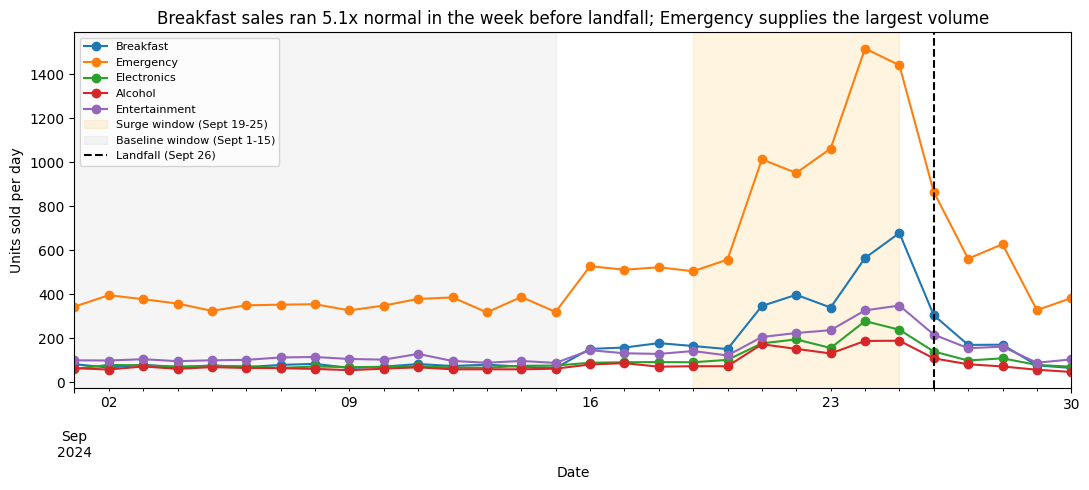

In [20]:
top5 = t.head(5).index.tolist()
daily = (demand[demand['category'].isin(top5)]
        .groupby(['date', 'category'])['quantity'].sum().unstack('category').fillna(0))

fig, ax = plt.subplots(figsize=(11, 5))
daily[top5].plot(ax=ax, marker='o')
ax.axvspan(*SURGE, alpha=0.12, color='orange', label='Surge window (Sept 19-25)')
ax.axvspan(*BASE, alpha=0.08, color='gray', label='Baseline window (Sept 1-15)')
ax.axvline(LANDFALL, color='black', linestyle='--', label='Landfall (Sept 26)')
ax.set_title(f'{top} sales ran {t.loc[top, "multiple"]:.1f}x normal in the week before landfall; Emergency supplies the largest volume')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold per day')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()